# Stage 2: Model Training and Evaluation

## Objective
Predict daily Units Sold for a selected synthetic store-product series.

## Evaluation Plan
- Forecast horizon: 7 days.
- Training: all records before the validation period.
- Validation: the next 28 days, used for model selection.
- Test: the final 28 days, reserved for final evaluation.
- Records remain in chronological order.
- Future observations must not enter model training or features.

In [25]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project = Path.cwd()

if not (project / "data/processed/retail_checked.csv").exists():
    project = project.parent

data_path = project / "data/processed/retail_checked.csv"

data = pd.read_csv(data_path, parse_dates=["Date"])

store_id = "S001"
product_id = "P0001"

selected = data[
    (data["Store ID"] == store_id)
    & (data["Product ID"] == product_id)
].copy()

selected = selected.sort_values("Date")

sales = selected.set_index("Date")["Units Sold"].astype(float)

assert not sales.empty, "Selected combination was not found."
assert sales.index.is_unique, "Duplicate dates found."

expected_dates = pd.date_range(
    sales.index.min(), sales.index.max(), freq="D"
)

assert sales.index.equals(expected_dates), "Missing daily dates found."

print("Selected:", store_id, product_id)
print("Total daily records:", len(sales))

Selected: S001 P0001
Total daily records: 731


## Chronological Data Split

The final 28 days are reserved for testing.
The preceding 28 days are used for validation.
All earlier observations form the training set.

The test results will not be used to choose or tune the model.

In [26]:
forecast_horizon = 7
validation_days = 28
test_days = 28

assert len(sales) > validation_days + test_days

train = sales.iloc[:-(validation_days + test_days)]
validation = sales.iloc[-(validation_days + test_days):-test_days]
test = sales.iloc[-test_days:]

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Start date": [
        train.index.min(),
        validation.index.min(),
        test.index.min()
    ],
    "End date": [
        train.index.max(),
        validation.index.max(),
        test.index.max()
    ],
    "Days": [len(train), len(validation), len(test)]
})

assert train.index.max() < validation.index.min()
assert validation.index.max() < test.index.min()

print(split_summary.to_string(index=False))

   Dataset Start date   End date  Days
  Training 2022-01-01 2023-11-06   675
Validation 2023-11-07 2023-12-04    28
      Test 2023-12-05 2024-01-01    28


## Naive Baseline: First Seven-Day Validation Forecast

The Naive method predicts the last observed sales value for every
day in the forecast horizon.

We first forecast the first seven validation days using training
data only. Actual validation sales are used afterward for evaluation.
The test set remains unused.

In [27]:
# Forecast the first seven validation days.
actual = validation.iloc[:forecast_horizon]

last_sale = train.iloc[-1]

naive_predictions = pd.Series(
    last_sale,
    index=actual.index,
    name="Predicted sales"
)

comparison = pd.DataFrame({
    "Actual sales": actual,
    "Predicted sales": naive_predictions
})

comparison["Absolute error"] = (
    comparison["Actual sales"] - comparison["Predicted sales"]
).abs()

mae = comparison["Absolute error"].mean()

rmse = (
    (comparison["Actual sales"] - comparison["Predicted sales"]) ** 2
).mean() ** 0.5

print("Last training-day sales:", last_sale)
print(comparison.to_string())
print("\nMAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

Last training-day sales: 49.0
            Actual sales  Predicted sales  Absolute error
Date                                                     
2023-11-07          22.0             49.0            27.0
2023-11-08         324.0             49.0           275.0
2023-11-09          75.0             49.0            26.0
2023-11-10         234.0             49.0           185.0
2023-11-11          59.0             49.0            10.0
2023-11-12         136.0             49.0            87.0
2023-11-13          24.0             49.0            25.0

MAE: 90.71
RMSE: 130.68


## Weekly Rolling Validation: Naive Baseline

Four seven-day forecasts cover the 28-day validation period.
At each weekly forecast origin, only sales already observed are used.
Actual sales from a completed week become available for the next
forecast. Test data remains unused.

In [28]:
weekly_results = []

for start in range(0, len(validation), forecast_horizon):

    # Sales available before this forecast week starts.
    history = pd.concat([train, validation.iloc[:start]])

    # Actual sales for the week being forecast.
    actual_week = validation.iloc[start:start + forecast_horizon]

    # Repeat the latest available sales value.
    predicted_week = pd.Series(
        history.iloc[-1],
        index=actual_week.index
    )

    week_result = pd.DataFrame({
        "Actual sales": actual_week,
        "Predicted sales": predicted_week
    })

    week_result["Week"] = start // forecast_horizon + 1
    weekly_results.append(week_result)

naive_validation = pd.concat(weekly_results)

error = (
    naive_validation["Actual sales"]
    - naive_validation["Predicted sales"]
)

validation_mae = error.abs().mean()
validation_rmse = (error.pow(2).mean()) ** 0.5

print(naive_validation.to_string())
print("\n28-day validation MAE:", round(validation_mae, 2))
print("28-day validation RMSE:", round(validation_rmse, 2))

            Actual sales  Predicted sales  Week
Date                                           
2023-11-07          22.0             49.0     1
2023-11-08         324.0             49.0     1
2023-11-09          75.0             49.0     1
2023-11-10         234.0             49.0     1
2023-11-11          59.0             49.0     1
2023-11-12         136.0             49.0     1
2023-11-13          24.0             49.0     1
2023-11-14          56.0             24.0     2
2023-11-15          55.0             24.0     2
2023-11-16          49.0             24.0     2
2023-11-17         416.0             24.0     2
2023-11-18         223.0             24.0     2
2023-11-19         105.0             24.0     2
2023-11-20         365.0             24.0     2
2023-11-21          21.0            365.0     3
2023-11-22         132.0            365.0     3
2023-11-23         226.0            365.0     3
2023-11-24          16.0            365.0     3
2023-11-25         371.0            365.

In [29]:
model_results = [{
    "Model": "Naive",
    "Validation MAE": validation_mae,
    "Validation RMSE": validation_rmse
}]

## Mean Baseline: Weekly Rolling Validation

The Mean method predicts the average of all sales observed before
each forecast week. This reduces dependence on one unusual last day.
The same validation dates and seven-day forecast horizon are used.

In [30]:
mean_weekly_results = []

for start in range(0, len(validation), forecast_horizon):

    history = pd.concat([train, validation.iloc[:start]])
    actual_week = validation.iloc[start:start + forecast_horizon]

    # Use the average of all sales available at this point.
    predicted_week = pd.Series(
        history.mean(),
        index=actual_week.index
    )

    week_result = pd.DataFrame({
        "Actual sales": actual_week,
        "Predicted sales": predicted_week
    })

    week_result["Week"] = start // forecast_horizon + 1
    mean_weekly_results.append(week_result)

mean_validation = pd.concat(mean_weekly_results)

error = (
    mean_validation["Actual sales"]
    - mean_validation["Predicted sales"]
)

mean_mae = error.abs().mean()
mean_rmse = (error.pow(2).mean()) ** 0.5

# Replace any earlier Mean result when this cell is rerun.
model_results = [
    result for result in model_results
    if result["Model"] != "Mean"
]

model_results.append({
    "Model": "Mean",
    "Validation MAE": mean_mae,
    "Validation RMSE": mean_rmse
})

print(pd.DataFrame(model_results).round(2).to_string(index=False))

Model  Validation MAE  Validation RMSE
Naive          133.86           181.65
 Mean           93.82           114.75


### Baseline Comparison
The Mean baseline achieved lower validation MAE and RMSE than
the Naive baseline. Using the historical average was more effective
than repeating the last observed sales value in this validation period.
Test performance has not yet been evaluated.

In [31]:
seasonal_weekly_results = []

for start in range(0, len(validation), forecast_horizon):

    history = pd.concat([train, validation.iloc[:start]])
    actual_week = validation.iloc[start:start + forecast_horizon]

    # Repeat the previous week's sales in the same day order.
    predicted_week = pd.Series(
        history.iloc[-7:].to_numpy(),
        index=actual_week.index
    )

    week_result = pd.DataFrame({
        "Actual sales": actual_week,
        "Predicted sales": predicted_week
    })

    week_result["Week"] = start // forecast_horizon + 1
    seasonal_weekly_results.append(week_result)

seasonal_validation = pd.concat(seasonal_weekly_results)

error = (
    seasonal_validation["Actual sales"]
    - seasonal_validation["Predicted sales"]
)

seasonal_mae = error.abs().mean()
seasonal_rmse = (error.pow(2).mean()) ** 0.5

model_results = [
    result for result in model_results
    if result["Model"] != "Seasonal Naive"
]

model_results.append({
    "Model": "Seasonal Naive",
    "Validation MAE": seasonal_mae,
    "Validation RMSE": seasonal_rmse
})

print(pd.DataFrame(model_results).round(2).to_string(index=False))

         Model  Validation MAE  Validation RMSE
         Naive          133.86           181.65
          Mean           93.82           114.75
Seasonal Naive          135.43           170.58


In [32]:
##%pip install statsmodels

## ARIMA: Weekly Rolling Validation

ARIMA(1,1,1) is used as an initial model configuration.
At each weekly forecast origin, the model is fitted using only
the sales observed before that week.

It forecasts the next seven days. The validation dates and
evaluation metrics remain the same as the baseline methods.
The test set remains unused.

In [33]:
from statsmodels.tsa.arima.model import ARIMA

arima_weekly_results = []

for start in range(0, len(validation), forecast_horizon):

    history = pd.concat([train, validation.iloc[:start]])
    history = history.asfreq("D")

    actual_week = validation.iloc[start:start + forecast_horizon]

    # Fit the model using available historical sales.
    model = ARIMA(history, order=(1, 1, 1))
    fitted_model = model.fit()

    if not fitted_model.mle_retvals.get("converged", True):
        raise RuntimeError(
            "ARIMA did not converge. Review the warning before continuing."
        )

    # Forecast the next week without using its actual sales.
    predicted_week = fitted_model.forecast(steps=len(actual_week))

    # Sales forecasts cannot be negative.
    predicted_week = predicted_week.clip(lower=0)

    assert predicted_week.index.equals(actual_week.index)

    week_result = pd.DataFrame({
        "Actual sales": actual_week,
        "Predicted sales": predicted_week
    })

    week_result["Week"] = start // forecast_horizon + 1
    arima_weekly_results.append(week_result)

arima_validation = pd.concat(arima_weekly_results)

error = (
    arima_validation["Actual sales"]
    - arima_validation["Predicted sales"]
)

arima_mae = error.abs().mean()
arima_rmse = (error.pow(2).mean()) ** 0.5

model_results = [
    result for result in model_results
    if result["Model"] != "ARIMA"
]

model_results.append({
    "Model": "ARIMA",
    "Validation MAE": arima_mae,
    "Validation RMSE": arima_rmse
})

print(pd.DataFrame(model_results).round(2).to_string(index=False))

         Model  Validation MAE  Validation RMSE
         Naive          133.86           181.65
          Mean           93.82           114.75
Seasonal Naive          135.43           170.58
         ARIMA           93.78           114.73


### ARIMA Validation Observation
ARIMA(1,1,1) produced slightly lower validation errors than the
Mean baseline. The MAE difference is only about 0.04 units,
so the results do not demonstrate a meaningful practical improvement.
Test performance has not yet been evaluated.

## XGBoost: Prepare Features from Past Sales

Lag features represent earlier sales observations.
The rolling average is shifted by one day so that it excludes
the sales value being predicted.

Feature preparation is first demonstrated on training data only.

In [34]:
def create_features(history):
    features = pd.DataFrame(index=history.index)

    features["lag_1"] = history.shift(1)
    features["lag_7"] = history.shift(7)
    features["lag_14"] = history.shift(14)

    features["mean_7"] = history.shift(1).rolling(7).mean()
    features["weekday"] = history.index.dayofweek

    features["target_sales"] = history

    return features.dropna()


training_features = create_features(train)

print(training_features.head().round(2).to_string())
print("\nTraining rows after feature preparation:",
      len(training_features))

            lag_1  lag_7  lag_14  mean_7  weekday  target_sales
Date                                                           
2022-01-15  177.0    2.0   127.0  109.29        5         176.0
2022-01-16  176.0  350.0    81.0  134.14        6          97.0
2022-01-17   97.0   36.0     5.0   98.00        0          69.0
2022-01-18   69.0   16.0    58.0  102.71        1         123.0
2022-01-19  123.0  104.0   147.0  118.00        2         211.0

Training rows after feature preparation: 661


In [35]:
##%pip install xgboost

In [36]:
##%pip install scikit-learn

## XGBoost: Weekly Rolling Validation

XGBoost learns a relationship between historical sales features
and the target day's sales.

Each seven-day forecast uses only information available at its
weekly forecast origin. Predictions are appended to the history
to construct features for subsequent forecast days.

In [37]:
from xgboost import XGBRegressor

feature_columns = ["lag_1", "lag_7", "lag_14", "mean_7", "weekday"]

xgb_weekly_results = []

for start in range(0, len(validation), forecast_horizon):

    history = pd.concat([train, validation.iloc[:start]])
    actual_week = validation.iloc[start:start + forecast_horizon]

    feature_table = create_features(history)

    X_train = feature_table[feature_columns]
    y_train = feature_table["target_sales"]

    # Initial settings, not tuned using the test set.
    model = XGBRegressor(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.05,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    )

    model.fit(X_train, y_train)

    # This history will grow using predictions, not future actual sales.
    forecast_history = history.copy()
    weekly_predictions = []

    for date in actual_week.index:

        next_day_features = pd.DataFrame({
            "lag_1": [forecast_history.iloc[-1]],
            "lag_7": [forecast_history.iloc[-7]],
            "lag_14": [forecast_history.iloc[-14]],
            "mean_7": [forecast_history.iloc[-7:].mean()],
            "weekday": [date.dayofweek]
        })

        prediction = float(
            model.predict(next_day_features[feature_columns])[0]
        )
        prediction = max(0.0, prediction)

        weekly_predictions.append(prediction)
        forecast_history.loc[date] = prediction

    week_result = pd.DataFrame({
        "Actual sales": actual_week,
        "Predicted sales": weekly_predictions
    })

    week_result["Week"] = start // forecast_horizon + 1
    xgb_weekly_results.append(week_result)

xgb_validation = pd.concat(xgb_weekly_results)

error = (
    xgb_validation["Actual sales"]
    - xgb_validation["Predicted sales"]
)

xgb_mae = error.abs().mean()
xgb_rmse = (error.pow(2).mean()) ** 0.5

model_results = [
    result for result in model_results
    if result["Model"] != "XGBoost"
]

model_results.append({
    "Model": "XGBoost",
    "Validation MAE": xgb_mae,
    "Validation RMSE": xgb_rmse
})

comparison_table = pd.DataFrame(model_results)

print(
    comparison_table
    .sort_values("Validation MAE")
    .round(2)
    .to_string(index=False)
)

         Model  Validation MAE  Validation RMSE
         ARIMA           93.78           114.73
          Mean           93.82           114.75
       XGBoost           99.35           118.70
         Naive          133.86           181.65
Seasonal Naive          135.43           170.58


## Validation Results and Model Selection

ARIMA achieved the lowest validation MAE and was selected for
final testing. Its improvement over the Mean baseline was negligible.
XGBoost did not outperform these methods in this experiment.

Model selection is now fixed. Test results will be used for
evaluation, not to change the selected model.

In [38]:
from statsmodels.tsa.arima.model import ARIMA

arima_test_weeks = []

for start in range(0, len(test), forecast_horizon):

    # Only observations available before this forecast week.
    history = pd.concat([
        train,
        validation,
        test.iloc[:start]
    ]).asfreq("D")

    actual_week = test.iloc[start:start + forecast_horizon]

    model = ARIMA(history, order=(1, 1, 1))
    fitted_model = model.fit()

    if not fitted_model.mle_retvals.get("converged", True):
        raise RuntimeError("ARIMA did not converge.")

    predicted_week = fitted_model.forecast(
        steps=len(actual_week)
    ).clip(lower=0)

    assert predicted_week.index.equals(actual_week.index)

    week_result = pd.DataFrame({
        "Actual sales": actual_week,
        "Predicted sales": predicted_week
    })

    week_result["Week"] = start // forecast_horizon + 1
    arima_test_weeks.append(week_result)

arima_test = pd.concat(arima_test_weeks)

test_error = (
    arima_test["Actual sales"]
    - arima_test["Predicted sales"]
)

test_mae = test_error.abs().mean()
test_rmse = (test_error.pow(2).mean()) ** 0.5

print(arima_test.round(2).to_string())
print("\nARIMA test MAE:", round(test_mae, 2))
print("ARIMA test RMSE:", round(test_rmse, 2))

            Actual sales  Predicted sales  Week
2023-12-05          66.0           138.84     1
2023-12-06          67.0           137.63     1
2023-12-07           2.0           137.65     1
2023-12-08         263.0           137.65     1
2023-12-09         174.0           137.65     1
2023-12-10         283.0           137.65     1
2023-12-11         143.0           137.65     1
2023-12-12         212.0           137.63     2
2023-12-13          65.0           137.70     2
2023-12-14          49.0           137.69     2
2023-12-15         162.0           137.69     2
2023-12-16         119.0           137.69     2
2023-12-17          55.0           137.69     2
2023-12-18          84.0           137.69     2
2023-12-19         242.0           137.96     3
2023-12-20         136.0           137.36     3
2023-12-21         174.0           137.37     3
2023-12-22         119.0           137.37     3
2023-12-23         188.0           137.37     3
2023-12-24         342.0           137.3

## Test Evaluation: Mean Baseline versus Selected ARIMA

The Mean baseline is evaluated using the same test dates,
weekly forecast origins and seven-day horizon as ARIMA.

This comparison assesses the selected model's value against a
simple baseline. It is not used to change the selected model.

In [39]:
mean_test_weeks = []

for start in range(0, len(test), forecast_horizon):

    # Only sales observed before the forecast week.
    history = pd.concat([
        train,
        validation,
        test.iloc[:start]
    ])

    actual_week = test.iloc[start:start + forecast_horizon]

    predicted_week = pd.Series(
        history.mean(),
        index=actual_week.index
    )

    week_result = pd.DataFrame({
        "Actual sales": actual_week,
        "Predicted sales": predicted_week
    })

    week_result["Week"] = start // forecast_horizon + 1
    mean_test_weeks.append(week_result)

mean_test = pd.concat(mean_test_weeks)

mean_test_error = (
    mean_test["Actual sales"]
    - mean_test["Predicted sales"]
)

mean_test_mae = mean_test_error.abs().mean()
mean_test_rmse = (mean_test_error.pow(2).mean()) ** 0.5

test_comparison = pd.DataFrame([
    {
        "Model": "ARIMA",
        "Test MAE": test_mae,
        "Test RMSE": test_rmse
    },
    {
        "Model": "Mean",
        "Test MAE": mean_test_mae,
        "Test RMSE": mean_test_rmse
    }
])

print(test_comparison.round(2).to_string(index=False))

Model  Test MAE  Test RMSE
ARIMA     72.96      86.06
 Mean     72.91      86.02


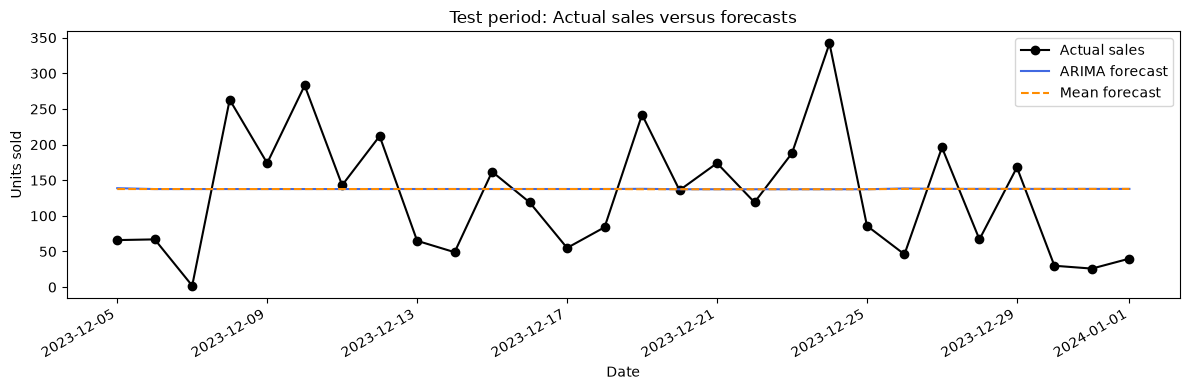

In [40]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    test.index, test,
    marker="o", label="Actual sales", color="black"
)

ax.plot(
    arima_test.index, arima_test["Predicted sales"],
    label="ARIMA forecast", color="royalblue"
)

ax.plot(
    mean_test.index, mean_test["Predicted sales"],
    label="Mean forecast", color="darkorange", linestyle="--"
)

ax.set(
    title="Test period: Actual sales versus forecasts",
    xlabel="Date",
    ylabel="Units sold"
)

ax.legend()
fig.autofmt_xdate()
fig.tight_layout()

figures_folder = project / "reports/figures"
figures_folder.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_folder / "06_test_forecast_comparison.png",
    dpi=160
)

plt.show()

## Final Evaluation Findings

ARIMA is being selected using the lowest validation MAE.
On the 28-day test period, ARIMA achieved MAE 72.96 and RMSE 86.06.
The Mean baseline achieved MAE 72.91 and RMSE 86.02.

The differences are negligible. Both methods produced nearly
constant forecasts and did not capture the large daily fluctuations.
This experiment does not demonstrate a meaningful advantage of
ARIMA over the Mean baseline.

These findings apply to the selected synthetic S001/P0001 series
and the evaluated dates, not to all retailers or products.

In [41]:
results_folder = project / "reports/model_results" / (
    f"{store_id}_{product_id}"
)
results_folder.mkdir(parents=True, exist_ok=True)

# Save model comparisons and split details.
pd.DataFrame(model_results).to_csv(
    results_folder / "validation_metrics.csv",
    index=False
)

test_comparison.to_csv(
    results_folder / "test_metrics.csv",
    index=False
)

split_summary.to_csv(
    results_folder / "data_split.csv",
    index=False
)

# Save dated predictions without rounding their values.
validation_predictions = pd.DataFrame({
    "Actual sales": validation,
    "Naive": naive_validation["Predicted sales"],
    "Mean": mean_validation["Predicted sales"],
    "Seasonal Naive": seasonal_validation["Predicted sales"],
    "ARIMA": arima_validation["Predicted sales"],
    "XGBoost": xgb_validation["Predicted sales"]
})

validation_predictions.to_csv(
    results_folder / "validation_predictions.csv",
    index_label="Date"
)

test_predictions = pd.DataFrame({
    "Actual sales": test,
    "ARIMA": arima_test["Predicted sales"],
    "Mean": mean_test["Predicted sales"]
})

test_predictions.to_csv(
    results_folder / "test_predictions.csv",
    index_label="Date"
)

print("Results saved in:", results_folder)

Results saved in: d:\MSDS\second_semester\Cloud Computing (CC)\project_1\retail-learning-stage-1\reports\model_results\S001_P0001


## Final Model: Refit and Forecast the Next Seven Days

After completing evaluation, ARIMA(1,1,1) is refitted on all
available sales observations.

The forecast starts immediately after the last recorded date.
Actual sales for these future dates are unavailable, so their
forecast errors cannot yet be calculated.

In [42]:
from statsmodels.tsa.arima.model import ARIMA
import numpy as np

# Use all available historical sales.
full_history = sales.asfreq("D")

final_model = ARIMA(full_history, order=(1, 1, 1))
final_fitted_model = final_model.fit()

if not final_fitted_model.mle_retvals.get("converged", True):
    raise RuntimeError("Final ARIMA model did not converge.")

# Predict the seven days after the last recorded date.
future_predictions = final_fitted_model.forecast(
    steps=forecast_horizon
).clip(lower=0)

assert np.isfinite(future_predictions.to_numpy()).all()

future_forecast = pd.DataFrame({
    "Date": future_predictions.index,
    "Store ID": store_id,
    "Product ID": product_id,
    "Model": "ARIMA",
    "Predicted units sold": future_predictions.to_numpy()
})

print(future_forecast.round(2).to_string(index=False))

print(
    "\nTotal seven-day forecast:",
    round(future_forecast["Predicted units sold"].sum(), 2),
    "units"
)

# Save full precision for later stock calculations.
results_folder = project / "reports/model_results" / (
    f"{store_id}_{product_id}"
)
results_folder.mkdir(parents=True, exist_ok=True)

future_forecast.to_csv(
    results_folder / "future_forecast.csv",
    index=False
)

print("\nSaved: future_forecast.csv")

      Date Store ID Product ID Model  Predicted units sold
2024-01-02     S001      P0001 ARIMA                138.25
2024-01-03     S001      P0001 ARIMA                137.24
2024-01-04     S001      P0001 ARIMA                137.25
2024-01-05     S001      P0001 ARIMA                137.25
2024-01-06     S001      P0001 ARIMA                137.25
2024-01-07     S001      P0001 ARIMA                137.25
2024-01-08     S001      P0001 ARIMA                137.25

Total seven-day forecast: 961.73 units

Saved: future_forecast.csv


Additional stock = max(0, forecast total + safety stock − available inventory)

## Calculate Additional Stock

The seven-day sales forecast is converted into an estimated
additional stock requirement.

Additional stock =
ceil(max(0, forecast total + safety stock - available inventory))

Inventory must be available at the forecast origin.
Safety stock is an assumed buffer.

This simplified calculation excludes incoming orders, supplier
lead times, storage capacity and ordering costs.
It does not place an order automatically.

In [43]:
import math

def calculate_stock_requirement(
    predictions,
    available_inventory,
    safety_stock
):
    values = [float(value) for value in predictions]

    if not values or not all(
        math.isfinite(value) and value >= 0
        for value in values
    ):
        raise ValueError("Forecast values must be finite and nonnegative.")

    for value in [available_inventory, safety_stock]:
        if not math.isfinite(value) or value < 0:
            raise ValueError(
                "Inventory and safety stock must be finite and nonnegative."
            )

    forecast_total = sum(values)

    additional_stock = math.ceil(
        max(0, forecast_total + safety_stock - available_inventory)
    )

    return forecast_total, additional_stock


# Assumed example inputs, not verified dataset values.
available_inventory = 300
safety_stock = 50

forecast_total, additional_stock = calculate_stock_requirement(
    future_forecast["Predicted units sold"],
    available_inventory,
    safety_stock
)

stock_result = pd.DataFrame([{
    "Store ID": store_id,
    "Product ID": product_id,
    "Forecast start": future_forecast["Date"].min(),
    "Forecast end": future_forecast["Date"].max(),
    "Forecast total": forecast_total,
    "Available inventory": available_inventory,
    "Assumed safety stock": safety_stock,
    "Additional units required": additional_stock
}])

print(stock_result.round(2).to_string(index=False))

stock_result.to_csv(
    results_folder / "stock_requirement_example.csv",
    index=False
)

Store ID Product ID Forecast start Forecast end  Forecast total  Available inventory  Assumed safety stock  Additional units required
    S001      P0001     2024-01-02   2024-01-08          961.73                  300                    50                        712


## Verify the Stock Calculation

Checks:
- The worked example requires 712 additional units.
- Sufficient inventory produces zero additional requirement.
- Negative inventory is rejected.

In [44]:
predictions = future_forecast["Predicted units sold"]

# Check 1: Our worked example.
_, required = calculate_stock_requirement(predictions, 300, 50)
assert required == 712

# Check 2: Inventory already covers forecast plus safety stock.
sufficient_inventory = math.ceil(predictions.sum() + 50)

_, required = calculate_stock_requirement(
    predictions, sufficient_inventory, 50
)
assert required == 0

# Check 3: Negative inventory must be rejected.
try:
    calculate_stock_requirement(predictions, -10, 50)
except ValueError:
    print("Negative inventory correctly rejected.")
else:
    raise AssertionError("Negative inventory was accepted.")

print("All three stock-calculation checks passed.")

Negative inventory correctly rejected.
All three stock-calculation checks passed.


## Reusable Forecasting Function

This function generates a forecast using the requested method.
It receives only the history available at the forecast origin.

The same function will support validation, testing and future
forecasting for different store-product combinations.
Each combination will be evaluated separately.

In [49]:
from datetime import timedelta

import numpy as np

def forecast_sales(history, method, horizon=7):

    history = history.astype(float).asfreq("D")

    if history.isna().any():
        raise ValueError("History contains missing values or dates.")

    if len(history) < 30:
        raise ValueError("At least 30 daily observations are required.")

    dates = pd.date_range(
        history.index[-1].to_pydatetime() + timedelta(days=1),
        periods=horizon,
        freq="D"
    )

    if method == "Naive":
        values = np.repeat(history.iloc[-1], horizon)

    elif method == "Mean":
        values = np.repeat(history.mean(), horizon)

    elif method == "Seasonal Naive":
        values = np.resize(history.iloc[-7:].to_numpy(), horizon)

    elif method == "ARIMA":
        fitted = ARIMA(history, order=(1, 1, 1)).fit()

        if not fitted.mle_retvals.get("converged", True):
            raise RuntimeError("ARIMA did not converge.")

        values = fitted.forecast(steps=horizon).to_numpy()

    elif method == "XGBoost":
        table = create_features(history)

        model = XGBRegressor(
            n_estimators=150,
            max_depth=3,
            learning_rate=0.05,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=1
        )

        model.fit(
            table[feature_columns],
            table["target_sales"]
        )

        buffer = history.copy()
        values = []

        for date in dates:
            inputs = pd.DataFrame({
                "lag_1": [buffer.iloc[-1]],
                "lag_7": [buffer.iloc[-7]],
                "lag_14": [buffer.iloc[-14]],
                "mean_7": [buffer.iloc[-7:].mean()],
                "weekday": [date.dayofweek]
            })

            prediction = max(
                0.0,
                float(model.predict(inputs[feature_columns])[0])
            )

            values.append(prediction)
            buffer.loc[date] = prediction

    else:
        raise ValueError(f"Unknown method: {method}")

    values = np.maximum(np.asarray(values, dtype=float), 0)

    if not np.isfinite(values).all():
        raise ValueError("Forecast contains invalid values.")

    return pd.Series(values, index=dates, name="Predicted sales")

In [50]:
# The basic use of the function is shown below. 
# The function can be called with any of the five methods, 
# and the forecast horizon can be adjusted as needed.
example_forecast = forecast_sales(
    history=train,
    method="Mean",
    horizon=7
)

print(example_forecast.round(2))

2023-11-07    137.21
2023-11-08    137.21
2023-11-09    137.21
2023-11-10    137.21
2023-11-11    137.21
2023-11-12    137.21
2023-11-13    137.21
Freq: D, Name: Predicted sales, dtype: float64


## Reusable Weekly Validation

Each method is evaluated over four seven-day validation forecasts.
Only observations available before each forecast week are used.

The method with the lowest validation MAE is selected.
RMSE and model name provide deterministic tie-breaking.
Test data is not used for selection.

In [51]:
def evaluate_validation(training_sales, validation_sales, horizon=7):

    methods = ["Naive", "Mean", "Seasonal Naive", "ARIMA", "XGBoost"]

    scores = []
    prediction_tables = []

    for method in methods:
        weekly_tables = []

        for start in range(0, len(validation_sales), horizon):

            history = pd.concat([
                training_sales,
                validation_sales.iloc[:start]
            ])

            actual_week = validation_sales.iloc[start:start + horizon]

            predictions = forecast_sales(
                history,
                method,
                horizon=len(actual_week)
            )

            assert predictions.index.equals(actual_week.index)

            week_table = pd.DataFrame({
                "Actual sales": actual_week,
                "Predicted sales": predictions
            })

            week_table["Week"] = start // horizon + 1
            weekly_tables.append(week_table)

        method_predictions = pd.concat(weekly_tables)

        error = (
            method_predictions["Actual sales"]
            - method_predictions["Predicted sales"]
        )

        scores.append({
            "Model": method,
            "Validation MAE": error.abs().mean(),
            "Validation RMSE": error.pow(2).mean() ** 0.5
        })

        method_predictions["Model"] = method
        prediction_tables.append(method_predictions)

    ranking = pd.DataFrame(scores).sort_values(
        ["Validation MAE", "Validation RMSE", "Model"]
    ).reset_index(drop=True)

    all_predictions = pd.concat(prediction_tables)

    return ranking, all_predictions

In [52]:
validation_ranking, validation_details = evaluate_validation(
    train,
    validation,
    horizon=7
)

selected_method = validation_ranking.iloc[0]["Model"]

print(validation_ranking.round(2).to_string(index=False))
print("\nValidation-selected method:", selected_method)

         Model  Validation MAE  Validation RMSE
         ARIMA           93.78           114.73
          Mean           93.82           114.75
       XGBoost           99.35           118.70
         Naive          133.86           181.65
Seasonal Naive          135.43           170.58

Validation-selected method: ARIMA


## Model Selection for Multiple Store-Product Combinations

Each combination uses its own sales history.

For each combination:
1. Reserve the final 28 days for testing.
2. Use the preceding 28 days for weekly validation.
3. Compare all five forecasting methods.
4. Select the method with the lowest validation MAE.
5. Save its validation results separately.

The first batch contains two combinations.
Test data is not used for model selection.

In [54]:
# List every available store-product combination.
combinations = (
    data[["Store ID", "Product ID"]]
    .drop_duplicates()
    .sort_values(["Store ID", "Product ID"])
    .reset_index(drop=True)
)

# Start with two combinations to verify the batch process.
batch = combinations

batch_folder = project / "reports/multi_series"
batch_folder.mkdir(parents=True, exist_ok=True)

batch_summary = []

for _, combination in batch.iterrows():

    current_store = combination["Store ID"]
    current_product = combination["Product ID"]

    print(f"Processing: {current_store}/{current_product}")

    pair_data = data[
        (data["Store ID"] == current_store)
        & (data["Product ID"] == current_product)
    ].copy()

    pair_data = pair_data.sort_values("Date")

    pair_sales = (
        pair_data.set_index("Date")["Units Sold"]
        .astype(float)
    )

    # Verify complete daily history before splitting.
    expected_dates = pd.date_range(
        pair_sales.index.min(),
        pair_sales.index.max(),
        freq="D"
    )

    assert pair_sales.index.is_unique, "Duplicate dates found."
    assert pair_sales.index.equals(expected_dates), "Missing dates found."
    assert len(pair_sales) >= 90 + validation_days + test_days

    pair_train = pair_sales.iloc[:-(validation_days + test_days)]
    pair_validation = pair_sales.iloc[
        -(validation_days + test_days):-test_days
    ]

    ranking, details = evaluate_validation(
        pair_train,
        pair_validation,
        horizon=forecast_horizon
    )

    winner = ranking.iloc[0]

    # Save results separately for each combination.
    pair_folder = batch_folder / f"{current_store}_{current_product}"
    pair_folder.mkdir(parents=True, exist_ok=True)

    ranking.to_csv(
        pair_folder / "validation_metrics.csv",
        index=False
    )

    details.to_csv(
        pair_folder / "validation_predictions.csv",
        index_label="Date"
    )

    batch_summary.append({
        "Store ID": current_store,
        "Product ID": current_product,
        "Observations": len(pair_sales),
        "Selected model": winner["Model"],
        "Validation MAE": winner["Validation MAE"],
        "Validation RMSE": winner["Validation RMSE"]
    })

    # Save progress after each completed combination.
    pd.DataFrame(batch_summary).to_csv(
        batch_folder / "batch_selection_summary.csv",
        index=False
    )

    print("Saved:", pair_folder.name)

batch_selection = pd.DataFrame(batch_summary)

print("\nBatch results:")
print(batch_selection.round(2).to_string(index=False))

Processing: S001/P0001
Saved: S001_P0001
Processing: S001/P0002
Saved: S001_P0002
Processing: S001/P0003
Saved: S001_P0003
Processing: S001/P0004
Saved: S001_P0004
Processing: S001/P0005
Saved: S001_P0005
Processing: S001/P0006
Saved: S001_P0006
Processing: S001/P0007
Saved: S001_P0007
Processing: S001/P0008
Saved: S001_P0008
Processing: S001/P0009
Saved: S001_P0009
Processing: S001/P0010
Saved: S001_P0010
Processing: S001/P0011
Saved: S001_P0011
Processing: S001/P0012
Saved: S001_P0012
Processing: S001/P0013
Saved: S001_P0013
Processing: S001/P0014
Saved: S001_P0014
Processing: S001/P0015
Saved: S001_P0015
Processing: S001/P0016
Saved: S001_P0016
Processing: S001/P0017
Saved: S001_P0017
Processing: S001/P0018
Saved: S001_P0018
Processing: S001/P0019
Saved: S001_P0019
Processing: S001/P0020
Saved: S001_P0020
Processing: S002/P0001
Saved: S002_P0001
Processing: S002/P0002
Saved: S002_P0002
Processing: S002/P0003
Saved: S002_P0003
Processing: S002/P0004
Saved: S002_P0004
Processing: S002

In [55]:
print("Completed combinations:", len(batch_selection))

print("\nSelected-model counts:")
print(batch_selection["Selected model"].value_counts().to_string())

Completed combinations: 100

Selected-model counts:
Selected model
Mean              41
ARIMA             28
XGBoost           23
Naive              7
Seasonal Naive     1


## Test Evaluation Across All Store-Product Combinations

Each combination's validation-selected method is evaluated on
its final 28 days using four weekly seven-day forecasts.

The Mean baseline is evaluated using the same procedure.
Model selections remain fixed regardless of test results.

In [56]:
def evaluate_test(earlier_sales, testing_sales, method, horizon=7):

    weekly_results = []

    for start in range(0, len(testing_sales), horizon):

        history = pd.concat([
            earlier_sales,
            testing_sales.iloc[:start]
        ])

        actual_week = testing_sales.iloc[start:start + horizon]

        predictions = forecast_sales(
            history,
            method,
            horizon=len(actual_week)
        )

        assert predictions.index.equals(actual_week.index)

        week_result = pd.DataFrame({
            "Actual sales": actual_week,
            "Predicted sales": predictions
        })

        week_result["Week"] = start // horizon + 1
        weekly_results.append(week_result)

    predictions = pd.concat(weekly_results)

    error = (
        predictions["Actual sales"]
        - predictions["Predicted sales"]
    )

    mae = error.abs().mean()
    rmse = error.pow(2).mean() ** 0.5

    return predictions, mae, rmse

In [57]:
# Read the saved selections; validation need not be rerun.
selections = pd.read_csv(
    batch_folder / "batch_selection_summary.csv"
)

assert len(selections) == len(combinations)
assert not selections.duplicated(["Store ID", "Product ID"]).any()

test_summary_rows = []

for _, selection in selections.iterrows():

    current_store = selection["Store ID"]
    current_product = selection["Product ID"]
    selected_model = selection["Selected model"]

    print(f"Testing: {current_store}/{current_product}")

    pair_data = data[
        (data["Store ID"] == current_store)
        & (data["Product ID"] == current_product)
    ].sort_values("Date")

    pair_sales = (
        pair_data.set_index("Date")["Units Sold"]
        .astype(float)
    )

    earlier_sales = pair_sales.iloc[:-test_days]
    testing_sales = pair_sales.iloc[-test_days:]

    selected_predictions, selected_mae, selected_rmse = evaluate_test(
        earlier_sales,
        testing_sales,
        selected_model,
        forecast_horizon
    )

    # Avoid repeating identical work if Mean was selected.
    if selected_model == "Mean":
        mean_predictions = selected_predictions.copy()
        baseline_mae = selected_mae
        baseline_rmse = selected_rmse
    else:
        mean_predictions, baseline_mae, baseline_rmse = evaluate_test(
            earlier_sales,
            testing_sales,
            "Mean",
            forecast_horizon
        )

    pair_folder = batch_folder / f"{current_store}_{current_product}"

    selected_predictions.to_csv(
        pair_folder / "selected_test_predictions.csv",
        index_label="Date"
    )

    mean_predictions.to_csv(
        pair_folder / "mean_test_predictions.csv",
        index_label="Date"
    )

    test_summary_rows.append({
        "Store ID": current_store,
        "Product ID": current_product,
        "Selected model": selected_model,
        "Selected test MAE": selected_mae,
        "Selected test RMSE": selected_rmse,
        "Mean test MAE": baseline_mae,
        "Mean test RMSE": baseline_rmse
    })

    # Save progress after each completed combination.
    pd.DataFrame(test_summary_rows).to_csv(
        batch_folder / "batch_test_summary.csv",
        index=False
    )

batch_test_summary = pd.DataFrame(test_summary_rows)

print("\nCompleted test evaluations:", len(batch_test_summary))
print(batch_test_summary.head().round(2).to_string(index=False))

Testing: S001/P0001
Testing: S001/P0002
Testing: S001/P0003
Testing: S001/P0004
Testing: S001/P0005
Testing: S001/P0006
Testing: S001/P0007
Testing: S001/P0008
Testing: S001/P0009
Testing: S001/P0010
Testing: S001/P0011
Testing: S001/P0012
Testing: S001/P0013
Testing: S001/P0014
Testing: S001/P0015
Testing: S001/P0016
Testing: S001/P0017
Testing: S001/P0018
Testing: S001/P0019
Testing: S001/P0020
Testing: S002/P0001
Testing: S002/P0002
Testing: S002/P0003
Testing: S002/P0004
Testing: S002/P0005
Testing: S002/P0006
Testing: S002/P0007
Testing: S002/P0008
Testing: S002/P0009
Testing: S002/P0010
Testing: S002/P0011
Testing: S002/P0012
Testing: S002/P0013
Testing: S002/P0014
Testing: S002/P0015
Testing: S002/P0016
Testing: S002/P0017
Testing: S002/P0018
Testing: S002/P0019
Testing: S002/P0020
Testing: S003/P0001
Testing: S003/P0002
Testing: S003/P0003
Testing: S003/P0004
Testing: S003/P0005
Testing: S003/P0006
Testing: S003/P0007
Testing: S003/P0008
Testing: S003/P0009
Testing: S003/P0010


## Overall Test Comparison

Compare the validation-selected methods against the Mean baseline
across all 100 combinations.

Selections remain unchanged. Average per-series errors describe
this dataset and evaluation period, not general accuracy for retailers.

In [58]:
# Read saved results, so testing does not need to be rerun.
batch_test_summary = pd.read_csv(
    batch_folder / "batch_test_summary.csv"
)

assert len(batch_test_summary) == len(combinations)
assert not batch_test_summary.duplicated(
    ["Store ID", "Product ID"]
).any()

# Positive difference means the selected method had lower MAE.
difference = (
    batch_test_summary["Mean test MAE"]
    - batch_test_summary["Selected test MAE"]
)

# Numerical tolerance, not a threshold for practical importance.
tolerance = 0.000001

print("Total combinations:", len(batch_test_summary))
print("Selected method had lower MAE:",
      int((difference > tolerance).sum()))
print("Mean baseline had lower MAE:",
      int((difference < -tolerance).sum()))
print("Numerically tied:",
      int((difference.abs() <= tolerance).sum()))

overall_comparison = pd.DataFrame([
    {
        "Approach": "Validation-selected methods",
        "Average per-series test MAE":
            batch_test_summary["Selected test MAE"].mean(),
        "Average per-series test RMSE":
            batch_test_summary["Selected test RMSE"].mean()
    },
    {
        "Approach": "Mean baseline",
        "Average per-series test MAE":
            batch_test_summary["Mean test MAE"].mean(),
        "Average per-series test RMSE":
            batch_test_summary["Mean test RMSE"].mean()
    }
])

print("\nOverall comparison:")
print(overall_comparison.round(2).to_string(index=False))

overall_comparison.to_csv(
    batch_folder / "overall_test_comparison.csv",
    index=False
)

Total combinations: 100
Selected method had lower MAE: 19
Mean baseline had lower MAE: 40
Numerically tied: 41

Overall comparison:
                   Approach  Average per-series test MAE  Average per-series test RMSE
Validation-selected methods                        89.80                        108.53
              Mean baseline                        86.52                        104.29


## Overall Test Findings

All 100 store-product combinations were evaluated.

Validation-selected methods achieved an average per-series test
MAE of 89.80 and RMSE of 108.53. The Mean baseline achieved lower
errors: MAE 86.52 and RMSE 104.29.

Selected methods had lower MAE in 19 combinations, while Mean had
lower MAE in 40. The remaining 41 combinations selected Mean and tied.

The model-selection procedure did not outperform the Mean baseline
overall on this test period. Model selections remain unchanged.
These results describe synthetic data, not verified retail performance.

## Future Forecasts for All Combinations

Each validation-selected method uses its complete series history
to forecast the seven days after its last recorded date.

Mean forecasts are also saved for transparent comparison.
Future actual sales are unavailable, so these forecasts have
no measured future error yet.

In [59]:
all_future_forecasts = []

for _, selection in selections.iterrows():

    current_store = selection["Store ID"]
    current_product = selection["Product ID"]
    selected_model = selection["Selected model"]

    pair_data = data[
        (data["Store ID"] == current_store)
        & (data["Product ID"] == current_product)
    ].sort_values("Date")

    pair_sales = (
        pair_data.set_index("Date")["Units Sold"]
        .astype(float)
    )

    selected_forecast = forecast_sales(
        pair_sales, selected_model, forecast_horizon
    )

    if selected_model == "Mean":
        mean_forecast = selected_forecast.copy()
    else:
        mean_forecast = forecast_sales(
            pair_sales, "Mean", forecast_horizon
        )

    pair_forecast = pd.DataFrame({
        "Date": selected_forecast.index,
        "Store ID": current_store,
        "Product ID": current_product,
        "Selected model": selected_model,
        "Selected forecast": selected_forecast.to_numpy(),
        "Mean forecast": mean_forecast.to_numpy()
    })

    pair_folder = batch_folder / f"{current_store}_{current_product}"

    pair_forecast.to_csv(
        pair_folder / "future_forecast.csv",
        index=False
    )

    all_future_forecasts.append(pair_forecast)

    # Save progress after every completed combination.
    combined_future = pd.concat(
        all_future_forecasts, ignore_index=True
    )

    combined_future.to_csv(
        batch_folder / "all_future_forecasts.csv",
        index=False
    )

assert len(combined_future) == len(selections) * forecast_horizon
assert not combined_future.duplicated(
    ["Store ID", "Product ID", "Date"]
).any()

print("Forecast combinations:",
      combined_future[["Store ID", "Product ID"]]
      .drop_duplicates().shape[0])
print("Forecast rows:", len(combined_future))
print("Start date:", combined_future["Date"].min())
print("End date:", combined_future["Date"].max())
print(combined_future.head(7).round(2).to_string(index=False))

Forecast combinations: 100
Forecast rows: 700
Start date: 2024-01-02 00:00:00
End date: 2024-01-08 00:00:00
      Date Store ID Product ID Selected model  Selected forecast  Mean forecast
2024-01-02     S001      P0001          ARIMA             138.25         137.31
2024-01-03     S001      P0001          ARIMA             137.24         137.31
2024-01-04     S001      P0001          ARIMA             137.25         137.31
2024-01-05     S001      P0001          ARIMA             137.25         137.31
2024-01-06     S001      P0001          ARIMA             137.25         137.31
2024-01-07     S001      P0001          ARIMA             137.25         137.31
2024-01-08     S001      P0001          ARIMA             137.25         137.31


## Prepare Data for the Streamlit Dashboard

Export historical sales, future forecasts, validation comparisons,
test results and dataset audit findings into an app_data folder.

The dashboard will display precomputed forecasts for all 100
combinations. Inventory inputs will update the stock calculation,
not retrain forecasting models.

In [60]:
import json

app_data = project / "app_data"
app_data.mkdir(parents=True, exist_ok=True)

# 1. Historical records for charts and selectors.
history_columns = [
    "Date", "Store ID", "Product ID",
    "Units Sold", "Inventory Level"
]

data[history_columns].to_csv(
    app_data / "history.csv",
    index=False
)

# 2. Future forecasts.
forecasts = pd.read_csv(
    batch_folder / "all_future_forecasts.csv",
    parse_dates=["Date"]
)

assert len(forecasts) == 700
assert not forecasts.duplicated(
    ["Store ID", "Product ID", "Date"]
).any()

forecast_counts = forecasts.groupby(
    ["Store ID", "Product ID"]
).size()

assert len(forecast_counts) == 100
assert forecast_counts.eq(7).all()

forecasts.to_csv(
    app_data / "future_forecasts.csv",
    index=False
)

# 3. Validation metrics for all five methods and all combinations.
validation_tables = []

for _, selection in selections.iterrows():

    current_store = selection["Store ID"]
    current_product = selection["Product ID"]

    pair_folder = batch_folder / f"{current_store}_{current_product}"

    metrics = pd.read_csv(
        pair_folder / "validation_metrics.csv"
    )

    metrics["Store ID"] = current_store
    metrics["Product ID"] = current_product

    validation_tables.append(metrics)

all_validation_metrics = pd.concat(
    validation_tables,
    ignore_index=True
)

assert len(all_validation_metrics) == 500

all_validation_metrics.to_csv(
    app_data / "validation_metrics.csv",
    index=False
)

# 4. Per-combination test results and selected methods.
test_results = pd.read_csv(
    batch_folder / "batch_test_summary.csv"
)

assert len(test_results) == 100

test_results.to_csv(
    app_data / "test_metrics.csv",
    index=False
)

# 5. Actual test sales and forecasts for comparison charts.
test_tables = []

for _, selection in selections.iterrows():

    current_store = selection["Store ID"]
    current_product = selection["Product ID"]

    pair_folder = batch_folder / f"{current_store}_{current_product}"

    selected_predictions = pd.read_csv(
        pair_folder / "selected_test_predictions.csv",
        parse_dates=["Date"]
    )

    mean_predictions = pd.read_csv(
        pair_folder / "mean_test_predictions.csv",
        parse_dates=["Date"]
    )

    assert selected_predictions["Date"].equals(
        mean_predictions["Date"]
    )
    assert selected_predictions["Actual sales"].equals(
        mean_predictions["Actual sales"]
    )

    selected_predictions = selected_predictions.rename(
        columns={"Predicted sales": "Selected forecast"}
    )

    selected_predictions["Mean forecast"] = (
        mean_predictions["Predicted sales"].to_numpy()
    )

    selected_predictions["Store ID"] = current_store
    selected_predictions["Product ID"] = current_product

    test_tables.append(selected_predictions)

all_test_predictions = pd.concat(test_tables, ignore_index=True)

assert len(all_test_predictions) == 2800

all_test_predictions.to_csv(
    app_data / "test_predictions.csv",
    index=False
)

# 6. Dataset quality findings.
quality = pd.read_csv(
    project / "reports/audit/quality_summary.csv"
)

quality.to_csv(app_data / "quality_summary.csv", index=False)

# 7. Explain the experiment and its limitations.
metadata = {
    "data_kind": "Synthetic demonstration data",
    "forecast_mode": "Precomputed offline forecasts",
    "forecast_horizon_days": 7,
    "validation_days": 28,
    "test_days": 28,
    "evaluation": "Weekly rolling forecasts",
    "selection_rule": "Lowest validation MAE, then RMSE and model name",
    "limitation": (
        "Product/category and store/region labels are inconsistent. "
        "Real retail usefulness has not been established."
    )
}

(app_data / "metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

print("Dashboard data prepared:")
for file in sorted(app_data.iterdir()):
    print("-", file.name)

Dashboard data prepared:
- future_forecasts.csv
- history.csv
- metadata.json
- quality_summary.csv
- test_metrics.csv
- test_predictions.csv
- validation_metrics.csv
